# Week 3: Learning the model (NumPy)

Week 2 inferred a distance from one sound with four numbers held fixed. Here the
animal hears two thousand sounds and learns those numbers, one at a time, by the
rules derived in the lessons. The simulation engine is the one the widgets on the
course pages run, line for line, so the numbers printed here are the numbers on
the pages.

### AI use

This course notebook was developed with substantial assistance from Claude
(Anthropic) and revised with Codex (OpenAI), under Jonathan Shock's direction.
AI contributed to explanations and code. See [AI use and attribution](https://shocklab.github.io/Active-Inference-course/ai-use.html)
for the review process and its limits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import cos, erf, exp, log, pi, sqrt

np.set_printoptions(precision=4, suppress=True)

## 1. The engine

Week 2's model: prior location `D_PRIOR`, prior variance `VAR_PRIOR`, sensory
variance `VAR_OBS` and source power `THETA`, with intensity `THETA / d**2`.

`settle` is Week 2's gradient ascent within one trial. Each step is capped at the
reciprocal of the Gauss-Newton curvature and never removes more than half the
current distance, which keeps a loud, near source from throwing the iteration into
instability. A finite step can change which local maximum the climb reaches, so the
lessons check their runs against the highest mode separately. `settle` stops when a
step falls below `TOL` and also reports whether that happened within `KMAX` steps.
`run` plays trials one after another, settling the state and then taking one
learning step on the parameter named by `learn`, and returns the number of trials
that did not settle as its fourth value. A trial that did not settle changes no
parameter. Variances are learned with the log-variance
step of Lesson 2, which cannot cross zero.

`post_r2` is the posterior average of the squared residual, used by the
posterior-averaged rule. When the likelihood's window of ten standard deviations
lies at intensities the prior can reach, it integrates over that window in residual
coordinates; for a quiet or negative observation it integrates over log distance
instead.

The generator `mulberry32` is a port of a common JavaScript one, so that the
widgets and this notebook draw the same random numbers.

In [2]:
D_PRIOR, VAR_PRIOR = 2.0, 1.0
U_OBS, VAR_OBS = 0.50, 0.10
THETA = 1.0


def npdf(x, m, v):
    return exp(-(x - m) ** 2 / (2 * v)) / sqrt(2 * pi * v)


def zp(dp, vp):
    return 0.5 * (1 + erf(dp / sqrt(2 * vp)))


ETA, KMAX, TOL = 0.05, 2000, 1e-12


def mulberry32(seed):
    """A 32-bit seeded generator, ported from the JavaScript original so that
    the widget and this file draw identical random numbers."""
    a = [seed & 0xFFFFFFFF]

    def imul(x, y):
        return ((x & 0xFFFFFFFF) * (y & 0xFFFFFFFF)) & 0xFFFFFFFF

    def rnd():
        a[0] = (a[0] + 0x6D2B79F5) & 0xFFFFFFFF
        t = imul(a[0] ^ (a[0] >> 15), 1 | a[0])
        t = ((t + imul(t ^ (t >> 7), 61 | t)) & 0xFFFFFFFF) ^ t
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296
    return rnd


def normal(r):
    u1 = r()
    u2 = r()
    return sqrt(-2.0 * log(1.0 - u1)) * cos(2.0 * pi * u2)


def erf_as(x):
    """Abramowitz and Stegun 7.1.26, absolute error below 1.5e-7. JavaScript
    has no erf, so the simulations on both sides use this one."""
    s = 1.0 if x >= 0 else -1.0
    x = abs(x)
    t = 1.0 / (1.0 + 0.3275911 * x)
    y = 1.0 - (((((1.061405429 * t - 1.453152027) * t) + 1.421413741) * t
                - 0.284496736) * t + 0.254829592) * t * exp(-x * x)
    return s * y


def trunc_ratio(dp, vp):
    """N(0; dp, vp) / Z_p, the truncation correction in the prior updates."""
    dens = exp(-dp * dp / (2.0 * vp)) / sqrt(2.0 * pi * vp)
    return dens / (0.5 * (1.0 + erf_as(dp / sqrt(2.0 * vp))))


def settle(u, dp, vp, th, vu, path=None):
    """Week 2's ascent on the log joint, run within one trial.

    Each step is capped at the reciprocal of the Gauss-Newton curvature, and
    never removes more than half the current distance. The caps keep a loud,
    near source from throwing the iteration into the instability of Week 2's
    Lesson 3. A finite step can change which stationary point the climb reaches,
    so the reported runs are checked against the highest mode separately.
    Returns the state, the number of steps, and whether the stopping rule was
    met before KMAX steps ran out.
    """
    d = dp
    k = 0
    ok = False
    while k < KMAX:
        gp = -2.0 * th / (d * d * d)
        grad = (dp - d) / vp + (u - th / (d * d)) / vu * gp
        cap = 1.0 / (1.0 / vp + gp * gp / vu)
        step = (ETA if ETA < cap else cap) * grad
        if step < -0.5 * d:
            step = -0.5 * d
        d = d + step
        k += 1
        if path is not None:
            path.append(d)
        if abs(step) < TOL:
            ok = True
            break
    return d, k, ok


def world_trial(r, loc, var, th, vu):
    """One trial of the generative process: a truncated-Gaussian distance and a
    noisy inverse-square intensity."""
    while True:
        d = loc + sqrt(var) * normal(r)
        if d > 0:
            break
    return d, th / (d * d) + sqrt(vu) * normal(r)


NY = 801


def post_r2(u, dp, vp, th, vu):
    """Posterior expectation of the squared sensory residual (u - g(d))^2.

    When the likelihood's window of ten standard deviations either side of u
    lies at intensities the prior can reach, the integral runs over that window
    in residual coordinates rho = u - y, where y = theta / d^2 and the
    likelihood has a fixed width; the Jacobian |dd/dy| of Week 2's Lesson 2
    enters as y^(-3/2). Otherwise (a quiet or negative u) it runs over log
    distance, from where the likelihood has fallen by e^-72 to past the furthest
    the mode can be pushed. Checked against a brute-force grid for Sigma_u from
    0.001 to 1 and u from -3 to 3: largest relative difference 5e-15.
    """
    sd = sqrt(vu)
    lw = []
    r2 = []
    if u - 10.0 * sd > th / ((dp + 12.0 * sqrt(vp)) * (dp + 12.0 * sqrt(vp))):
        h = 20.0 * sd / (NY - 1)
        for i in range(NY):
            rho = -10.0 * sd + i * h
            y = u - rho
            d = sqrt(th / y)
            lw.append(-rho * rho / (2.0 * vu) - (d - dp) * (d - dp) / (2.0 * vp) - 1.5 * log(y))
            r2.append(rho * rho)
    else:
        up = u if u > 0.0 else 0.0
        da = sqrt(th / (up + 12.0 * sd))
        c = 2.0 * th * vp * (th / (dp * dp) + abs(u)) / vu
        db = dp + 12.0 * sqrt(vp) + sqrt(sqrt(c))
        if da > 0.5 * db:
            da = 0.5 * db
        sa = log(da)
        h = (log(db) - sa) / (NY - 1)
        for i in range(NY):
            q = sa + i * h
            d = exp(q)
            res = u - th / (d * d)
            lw.append(-res * res / (2.0 * vu) - (d - dp) * (d - dp) / (2.0 * vp) + q)
            r2.append(res * res)
    mx = max(lw)
    s0 = 0.0
    s2 = 0.0
    for i in range(NY):
        w = exp(lw[i] - mx) * (0.5 if i == 0 or i == NY - 1 else 1.0)
        s0 += w
        s2 += w * r2[i]
    return s2 / s0


def run(seed, n, world, model, learn, beta, rule="point", keep_paths=()):
    """Trials one after another. `world` is (location, variance, theta, Sigma_u)
    of the process; `model` holds the animal's (dp, vp, th, vu). Only the
    parameter named by `learn` changes."""
    r = mulberry32(seed)
    dp, vp, th, vu = model["dp"], model["vp"], model["th"], model["vu"]
    hist, errs, paths, unsettled = [], [], {}, 0
    for i in range(n):
        dtrue, u = world_trial(r, *world)
        path = [dp] if i in keep_paths else None
        dh, _, ok = settle(u, dp, vp, th, vu, path)
        if not ok:
            unsettled += 1
        if path is not None:
            paths[i] = path
        ep = (dp - dh) / vp
        eu = (u - th / (dh * dh)) / vu
        errs.append((ep, eu, dh, u, {"dp": dp, "vp": vp, "th": th, "vu": vu}[learn]))
        if not ok:
            pass                     # inference unfinished: no parameter update
        elif learn == "dp":
            dp = dp + beta * (-ep - trunc_ratio(dp, vp))
        elif learn == "th":
            th = th + beta * eu / (dh * dh)
        elif learn == "vu":
            res = u - th / (dh * dh)
            r2 = res * res if rule == "point" else post_r2(u, dp, vp, th, vu)
            vu = vu * exp(beta * 0.5 * (r2 / vu - 1.0))
        elif learn == "vp":
            dev = dh - dp
            vp = vp * exp(beta * (0.5 * (dev * dev / vp - 1.0)
                                  + 0.5 * dp * trunc_ratio(dp, vp)))
        hist.append({"dp": dp, "vp": vp, "th": th, "vu": vu}[learn])
    return hist, errs, paths, unsettled


WEEK2 = {"dp": D_PRIOR, "vp": VAR_PRIOR, "th": THETA, "vu": VAR_OBS}
N_TRIALS = 2000

## 2. The derivatives, checked

Lesson 2 derived the derivatives of the log joint with respect to the prior
location, the two variances and, in Lesson 3, the source power. Here `ell` is the
log joint with every constant restored, including the truncation normaliser, and
each hand-derived derivative at Week 2's mode is compared with a central finite
difference.

In [3]:
def ell(d, u=U_OBS, dp=D_PRIOR, vp=VAR_PRIOR, th=THETA, vu=VAR_OBS):
    return (-(d - dp) ** 2 / (2 * vp) - 0.5 * log(2 * pi * vp) - log(zp(dp, vp))
            - (u - th / d ** 2) ** 2 / (2 * vu) - 0.5 * log(2 * pi * vu))


dh, _, _ = settle(U_OBS, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)
ep = (D_PRIOR - dh) / VAR_PRIOR
eu = (U_OBS - THETA / dh ** 2) / VAR_OBS
zeta = npdf(0, D_PRIOR, VAR_PRIOR) / zp(D_PRIOR, VAR_PRIOR)

by_hand = {
    "dp": -ep - zeta,
    "vp": 0.5 * (ep ** 2 - 1 / VAR_PRIOR) + D_PRIOR * zeta / (2 * VAR_PRIOR),
    "vu": 0.5 * (eu ** 2 - 1 / VAR_OBS),
    "th": eu / dh ** 2,
}
e = 1e-6
for name, h in by_hand.items():
    up = ell(dh, **{name: {"dp": D_PRIOR, "vp": VAR_PRIOR, "vu": VAR_OBS, "th": THETA}[name] + e})
    dn = ell(dh, **{name: {"dp": D_PRIOR, "vp": VAR_PRIOR, "vu": VAR_OBS, "th": THETA}[name] - e})
    print(f"{name}:  by hand {h: .6f}   finite difference {(up - dn) / (2 * e): .6f}")
print(f"mode {dh:.4f}")

dp:  by hand -0.505212   finite difference -0.505212
vp:  by hand -0.343518   finite difference -0.343518
vu:  by hand -4.648993   finite difference -4.648993
th:  by hand  0.348730   finite difference  0.348730
mode 1.5500


## 3. Two timescales

The widget of Lesson 1: sources placed around 3 rather than 2, a sharp ear with
sensory variance 0.01 in both the world and the model, and the prior location
learned with learning rate 0.01.

trials that did not settle: 0
first trial settles in 178 steps, at d = 2.8819
prior location after 200 trials 2.3903
mean over trials 1001-2000      2.4946


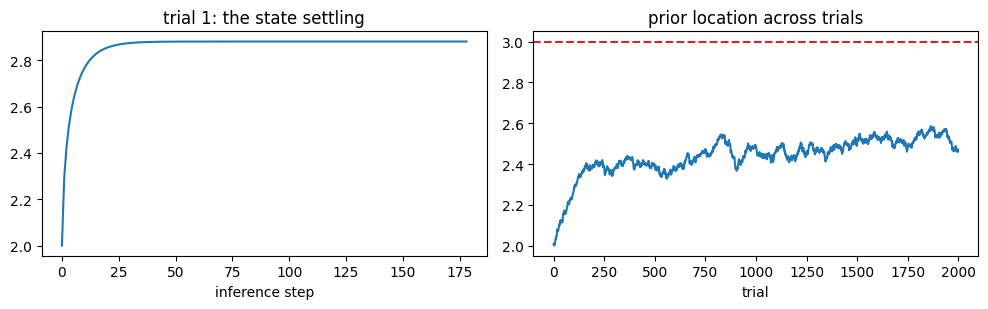

In [4]:
w1_world = (3.0, VAR_PRIOR, THETA, 0.01)
h1, e1, p1, bad1 = run(7, N_TRIALS, w1_world, dict(WEEK2, vu=0.01), "dp", 0.01, keep_paths=(0, 1999))
print(f"trials that did not settle: {bad1}")

print(f"first trial settles in {len(p1[0]) - 1} steps, at d = {p1[0][-1]:.4f}")
print(f"prior location after 200 trials {h1[199]:.4f}")
print(f"mean over trials 1001-2000      {np.mean(h1[1000:]):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(p1[0]); ax[0].set(title="trial 1: the state settling", xlabel="inference step")
ax[1].plot(h1); ax[1].axhline(3.0, ls="--", c="C3")
ax[1].set(title="prior location across trials", xlabel="trial")
plt.tight_layout(); plt.show()

The prior location settles below 3. Lesson 4 explains why, and the last section of
this notebook computes the same kind of shortfall exactly in a model where it can
be done by hand.

## 4. A wrong link

Lesson 3's widget: the world's sources are twice as powerful as the animal believes.
Then the problem page's variant: a world half as powerful. For each, run with
learning off and on, and average the two errors and the learning signal
`eu / dh**2` over the last 200 trials.

In [5]:
def window_means(errs, w=200):
    a = np.array(errs)
    return a[-w:, 0].mean(), a[-w:, 1].mean(), (a[-w:, 1] / a[-w:, 2] ** 2).mean()


for th_world in (2.0, 0.5):
    world = (D_PRIOR, VAR_PRIOR, th_world, VAR_OBS)
    for beta in (0.0, 0.01):
        h, errs, _, bad = run(7, N_TRIALS, world, dict(WEEK2), "th", beta)
        assert bad == 0
        mp, mu, ms = window_means(errs)
        print(f"world power {th_world}, learning {'on ' if beta else 'off'}: final power {h[-1]:.4f}   "
              f"prior error {mp: .4f}   sensory error {mu: .4f}   learning signal {ms: .4f}")

_, errs_true, _, _ = run(7, N_TRIALS, (D_PRIOR, VAR_PRIOR, 2.0, VAR_OBS), dict(WEEK2, th=2.0), "th", 0.0)
a = np.array(errs_true)
print(f"model exactly right, all trials: prior error {a[:, 0].mean():.4f}, sensory error {a[:, 1].mean():.4f}")

world power 2.0, learning off: final power 1.0000   prior error  0.6455   sensory error -0.0347   learning signal  0.2271


world power 2.0, learning on : final power 1.8463   prior error  0.3507   sensory error -0.4484   learning signal  0.0310


world power 0.5, learning off: final power 1.0000   prior error  0.1271   sensory error -0.9460   learning signal -0.0481
world power 0.5, learning on : final power 0.8799   prior error  0.1984   sensory error -0.7716   learning signal  0.0113


model exactly right, all trials: prior error 0.2182, sensory error -0.6812


Here the learning signal changes sign with the direction of the mismatch and the two
errors do not. Lesson 3 shows that this is not guaranteed for every quieter world:
at a world power of 0.99 the point rule still pushes the power up. Neither error
averages to zero even when the model is exactly right.

## 5. Learning the sensory variance two ways

The world's sensory variance is 0.3; the animal starts from Week 2's 0.1. The point
rule squares the residual at the mode. The posterior-averaged rule replaces that
square by its average over the posterior, computed by `post_r2`.

trials that did not settle: 0 and 0
              point: final 0.0892, mean over 1001-2000 0.0957, ear's share 0.395
 posterior-averaged: final 0.3000, mean over 1001-2000 0.2933, ear's share 0.176
ear's share at the start 0.385, at the truth 0.172


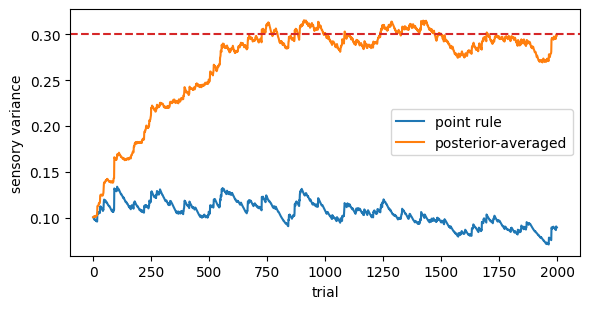

In [6]:
world3 = (D_PRIOR, VAR_PRIOR, THETA, 0.3)
hp, _, _, bp = run(7, N_TRIALS, world3, dict(WEEK2), "vu", 0.01, "point")
he, _, _, be = run(7, N_TRIALS, world3, dict(WEEK2), "vu", 0.01, "post")
print(f"trials that did not settle: {bp} and {be}")


def ear_share(vu, d=D_PRIOR, vp=VAR_PRIOR, th=THETA):
    s = (2 * th / d ** 3) ** 2 / vu
    return s / (1 / vp + s)


for name, h in (("point", hp), ("posterior-averaged", he)):
    m = np.mean(h[1000:])
    print(f"{name:>19}: final {h[-1]:.4f}, mean over 1001-2000 {m:.4f}, ear's share {ear_share(m):.3f}")
print(f"ear's share at the start {ear_share(0.1):.3f}, at the truth {ear_share(0.3):.3f}")

plt.figure(figsize=(6, 3.2))
plt.plot(hp, label="point rule"); plt.plot(he, label="posterior-averaged")
plt.axhline(0.3, ls="--", c="C3"); plt.legend(); plt.xlabel("trial"); plt.ylabel("sensory variance")
plt.tight_layout(); plt.show()

These are averages of one run. Lesson 4 computes, by quadrature over the world, that
the point rule's expected update vanishes just above the starting value of 0.1, so
the point-rule average landing slightly below 0.1 here is this run's fluctuation. The
robust finding is that the point rule stays near 0.1 while the world's value is 0.3.

Gaussian noise can make an observation negative, and `post_r2` must still integrate
over the posterior then. For a negative observation every prediction is positive, so
the squared residual is at least the square of the observation; the two values below
are checked against an independent integration.

In [7]:
for u, vu, ref in ((-1.0, 0.005, 1.07842137), (-2.0, 0.005, 4.11541549)):
    print(f"u = {u}, model variance {vu}: post_r2 = {post_r2(u, D_PRIOR, VAR_PRIOR, THETA, vu):.8f}"
          f"   independent {ref}   u squared {u * u}")

u = -1.0, model variance 0.005: post_r2 = 1.07842137   independent 1.07842137   u squared 1.0
u = -2.0, model variance 0.005: post_r2 = 4.11541549   independent 4.11541549   u squared 4.0


## 6. The linear case, exactly

In the linear Gaussian model of Lesson 4, the point rule's stationary points for the
prior variance are the roots of
`x**2 + (var_u - S) * x + var_u**2 = 0`, where `S` is the world's prior variance.
Compare them with a long simulation, and watch the variance collapse when
`S < 3 * var_u`.

In [8]:
def lin_roots(S, vu):
    disc = (S - vu) ** 2 - 4 * vu ** 2
    if S - vu <= 0 or disc < 0:
        return None
    return ((S - vu) - sqrt(disc)) / 2, ((S - vu) + sqrt(disc)) / 2


def lin_learn(rule, S=1.0, vu=0.1, n=60000, seed=13, beta=0.01, x0=1.0):
    r = mulberry32(seed)
    x, xs = x0, []
    for _ in range(n):
        d = D_PRIOR + sqrt(S) * normal(r)
        u = d + sqrt(vu) * normal(r)
        dh = (vu * D_PRIOR + x * u) / (x + vu)
        sq = (dh - D_PRIOR) ** 2
        if rule == "post":
            sq += x * vu / (x + vu)
        x = x * exp(beta * 0.5 * (sq / x - 1.0))
        xs.append(x)
    return xs


print("roots with S = 1, var_u = 0.1:", lin_roots(1.0, 0.1))
print(f"point rule, mean of the last 40000 trials:              {np.mean(lin_learn('point')[20000:]):.4f}")
print(f"posterior-averaged rule, mean of the last 40000 trials: {np.mean(lin_learn('post')[20000:]):.4f}")
print("roots with S = 1, var_u = 0.5:", lin_roots(1.0, 0.5))
print(f"point rule after 4000 trials with var_u = 0.5: {lin_learn('point', vu=0.5, n=4000)[-1]:.3e}")

roots with S = 1, var_u = 0.1: (0.011251780630393893, 0.8887482193696061)
point rule, mean of the last 40000 trials:              0.9080


posterior-averaged rule, mean of the last 40000 trials: 1.0188
roots with S = 1, var_u = 0.5: None
point rule after 4000 trials with var_u = 0.5: 4.529e-07
